# 03 · First conformal test — split conformal vs conformalized quantile regression (FD001)

**Goal.** Turn the LightGBM point prediction into a 90 % interval with two MAPIE v1 methods and check
the result on engines never seen during training or calibration.

- **SCP** — `SplitConformalRegressor(prefit=True)` around the fitted LightGBM. Conformity score =
  |y − ŷ| on the calibration engines; its (1 − α) quantile becomes a constant half-width.
- **CQR** — `ConformalizedQuantileRegressor(prefit=True)` around three LightGBM quantile models
  (`objective="quantile"`, α = 0.05 / 0.95 / 0.5). The calibration residuals shift the two quantile
  curves outward (or inward) by a constant, so widths vary with the engine's state.

Both are conformalised on the **rows of the 15 calibration engines** — engines are approximately
exchangeable, rows within an engine are not.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import SEED, RUL_CAP, CONFIDENCE_LEVEL
from src.experiment import prepare, fit_point_models, fit_conformal, evaluate_conformal, log_official
from src.conformal import predict_interval
from src.evaluate import coverage, mean_width
from src.results import load_runs
from src.plots import save

pd.set_option("display.width", 160)
pd.set_option("display.precision", 3)

In [2]:
data = prepare("FD001", seed=SEED)
models = fit_point_models(data, seed=SEED)
cps, (q_lower, q_upper, q_median) = fit_conformal(data, models["lgbm"], seed=SEED, confidence_level=CONFIDENCE_LEVEL)
table, preds = evaluate_conformal(cps, data)
table.pivot(index="model", columns="eval_set", values=["rmse", "coverage", "mean_width"]).round(3)

rmse         coverage        mean_width        
eval_set official    test official   test   official    test
model                                                       
lgbm_cqr   19.957  17.862     0.86  0.858     47.306  44.374
lgbm_scp   19.214  18.049     0.83  0.851     44.136  40.918

**Interpretation.** Neither method reaches the nominal 0.90 on this seed: SCP covers 0.85 of the
internal-test rows and 0.83 of the official engines, CQR 0.86 on both, with CQR intervals ≈3 cycles
wider on average. With only 15 calibration engines the conformal guarantee is a statement *on average
over calibration draws*, so a single seed can fall short — notebook 05 checks the average over seeds.
CQR also has the lower official RMSE here (19.96 vs 19.21 is in SCP's favour on the official set but
CQR wins on the internal test), so neither method dominates on one seed.

## SCP inside: one calibration quantile, one width

calibration rows: 2909   finite-sample 90% quantile of |residual|: 25.75 cycles
unclipped SCP width on the official set, unique values: [51.49]


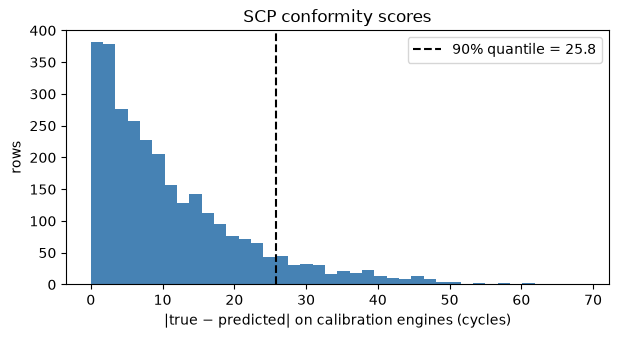

In [3]:
lgbm = models["lgbm"]
abs_res = np.abs(data.y("cal").to_numpy() - lgbm.predict(data.X("cal")))
n_cal = len(abs_res)
q_hat = np.quantile(abs_res, min(1.0, np.ceil((n_cal + 1) * CONFIDENCE_LEVEL) / n_cal), method="higher")
_, lo_raw, hi_raw = predict_interval(cps["lgbm_scp"], data.X("official"), clip=None)
print(f"calibration rows: {n_cal}   finite-sample {CONFIDENCE_LEVEL:.0%} quantile of |residual|: {q_hat:.2f} cycles")
print("unclipped SCP width on the official set, unique values:", np.unique((hi_raw - lo_raw).round(2)))

fig, ax = plt.subplots(figsize=(7, 3.3))
ax.hist(abs_res, bins=40, color="steelblue")
ax.axvline(q_hat, color="k", ls="--", label=f"{CONFIDENCE_LEVEL:.0%} quantile = {q_hat:.1f}")
ax.set(xlabel="|true − predicted| on calibration engines (cycles)", ylabel="rows", title="SCP conformity scores")
ax.legend()
save(fig, "conformal_fd001_scp_residuals.png")

**Interpretation.** SCP with the absolute-residual score produces one half-width for every engine —
the finite-sample 90 % quantile of the calibration residuals, 25.8 cycles, hence a constant unclipped
width of 51.5 — so the only reason widths differ in the tables is the clip to the feasible range
[0, 125]. The residual histogram is heavy-tailed: most rows are within 10 cycles, a minority
(early-life rows predicted below the cap) is off by 40–60, and it is that tail that fixes the width
for every engine, however healthy or degraded it is. This is exactly the limitation CQR addresses.

## CQR inside: quantile models before and after conformalisation

In [4]:
X_off, y_off = data.X("official"), data.y("official")
raw_lo, raw_hi = q_lower.predict(X_off), q_upper.predict(X_off)
cqr_pred, cqr_lo, cqr_hi = preds[("lgbm_cqr", "official")]
_, cqr_lo_raw, cqr_hi_raw = predict_interval(cps["lgbm_cqr"], X_off, clip=None)

pd.DataFrame({
    "quantile models alone": {"coverage": coverage(y_off, raw_lo, raw_hi), "mean_width": mean_width(raw_lo, raw_hi)},
    "CQR, unclipped":        {"coverage": coverage(y_off, cqr_lo_raw, cqr_hi_raw), "mean_width": mean_width(cqr_lo_raw, cqr_hi_raw)},
    "CQR, clipped to [0, 125]": {"coverage": coverage(y_off, cqr_lo, cqr_hi), "mean_width": mean_width(cqr_lo, cqr_hi)},
}).T.round(3)

,coverage,mean_width
quantile models alone,0.81,46.451
"CQR, unclipped",0.86,47.501
"CQR, clipped to [0, 125]",0.86,47.306


In [5]:
crossing_cal = (q_lower.predict(data.X("cal")) > q_upper.predict(data.X("cal"))).mean()
crossing_off = (raw_lo > raw_hi).mean()
print(f"quantile crossing (lower > upper): {crossing_cal:.1%} of calibration rows, {crossing_off:.1%} of official engines")
print(f"conformal correction added to each side: {np.mean((cqr_hi_raw - cqr_lo_raw) - (raw_hi - raw_lo)) / 2:+.2f} cycles")

quantile crossing (lower > upper): 0.1% of calibration rows, 1.0% of official engines
conformal correction added to each side: +0.52 cycles


**Interpretation.** The two quantile LightGBMs alone reach 0.81 on the official engines instead of the
0.90 they were trained for: a pinball loss fitted on the training engines is optimistic on unseen ones.
Conformalisation pushes the bounds outward by ≈0.5 cycles per side and recovers 0.86 — a small,
data-driven correction, which is the point of CQR. Crossings (lower above upper) affect 1 % of the
official engines; MAPIE handles them, but they show that independently fitted quantile models are not
automatically coherent. Clipping to [0, 125] removes only impossible width and leaves coverage untouched.

**Implementation note.** The three quantile models are built with `boost_from_average=False`
(`src/models.py`). LightGBM otherwise initialises a quantile model at the α-quantile of the label,
which for the capped RUL target is the cap itself whenever α ≳ 0.6 (≈39 % of training rows sit at 125).
From that start every row has the same pinball gradient, no split improves the loss, and the α = 0.75
model collapsed to a constant 125 — which silently inflated CQR's intervals. `fit_quantile_trio` now
warns if any quantile model comes out constant.

## Per-engine coverage on the internal test engines

,lgbm_scp,lgbm_cqr
mean,0.84,0.86
std,0.12,0.15
min,0.60,0.44
max,0.98,0.98


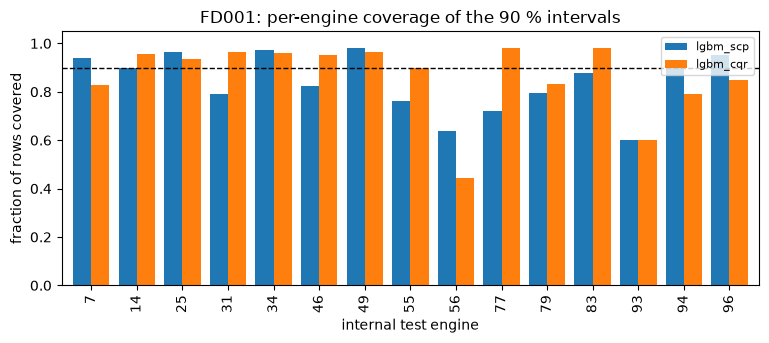

In [6]:
y_t, g_t = data.y("test"), data.groups("test")
per_engine = pd.DataFrame({
    name: pd.Series((lo <= y_t.to_numpy()) & (y_t.to_numpy() <= hi), index=y_t.index).groupby(g_t).mean()
    for (name, eval_set), (_, lo, hi) in preds.items() if eval_set == "test"
})
fig, ax = plt.subplots(figsize=(9, 3.3))
per_engine.plot.bar(ax=ax, width=0.8)
ax.axhline(CONFIDENCE_LEVEL, color="k", ls="--", lw=1)
ax.set(xlabel="internal test engine", ylabel="fraction of rows covered", title="FD001: per-engine coverage of the 90 % intervals", ylim=(0, 1.05))
ax.legend(fontsize=8)
save(fig, "conformal_fd001_per_engine_coverage.png")
per_engine.describe().loc[["mean", "std", "min", "max"]].round(2)

**Interpretation.** Coverage is far from uniform across engines: the per-engine mean is ≈0.85 for both
methods but the spread runs from ≈0.45 to ≈0.98 (std 0.12–0.15). Residuals within one engine are
strongly autocorrelated — when the model misreads an engine it stays wrong for many consecutive
cycles — so a marginal 90 % guarantee says nothing about any individual engine. This is the
conditional-coverage question of the thesis, and with 15 test engines it is measured very noisily.

## SCP vs CQR on this seed

In [7]:
comparison = table.pivot(index="model", columns="eval_set", values=["rmse", "nasa_score", "coverage", "mean_width"]).round(3)
comparison

rmse         nasa_score            coverage        mean_width        
eval_set official    test   official       test official   test   official    test
model                                                                             
lgbm_cqr   19.957  17.862   1471.978  45176.283     0.86  0.858     47.306  44.374
lgbm_scp   19.214  18.049   1387.644  31960.075     0.83  0.851     44.136  40.918

**Interpretation.** On seed 0 CQR reaches higher coverage (0.86 vs 0.83 on the official engines) at the
cost of ≈3 cycles more average width, and the two are within noise of each other on the internal test.
Mean width alone hides the real difference: SCP's width is the same for every engine, CQR's adapts to
the engine's state (notebook 04). Since neither method covers 0.90 here, and one seed means 15
calibration engines and 100 test engines, no conclusion should be drawn before notebook 05.

In [8]:
log_official(table, "FD001", SEED)
load_runs()

,subset,model,seed,rmse,nasa_score,coverage,mean_width,n_test
0,FD001,linear,0,20.899,1712.89,NaN,NaN,100
1,FD001,lgbm,0,19.214,1387.64,NaN,NaN,100
2,FD001,lgbm_scp,0,19.214,1387.64,0.83,44.136,100
3,FD001,lgbm_cqr,0,19.957,1471.98,0.86,47.306,100
